In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("C:\\Users\\Vasu H S\\supply chain\\Dataset\\E-commerce_Delivery_Shipping_Data_2026.csv")

# Display first 5 rows
df.head()

,order_id,order_date,customer_id,customer_segment,customer_city,customer_country,warehouse_id,warehouse_city,product_category,product_weight_kg,...,package_size,payment_method,order_priority,weather_condition,customer_rating,return_requested,return_reason,delivery_attempts,warehouse_processing_hours,tracking_status
0,ORD-000001,2026-11-15,CUS-002353,Small Business,Tokyo,Japan,WH-004,Toronto,Home & Kitchen,8.23,...,Large,Digital Wallet,Normal,Snow,3,Yes,Late Delivery,2,25.1,Delivered
1,ORD-000002,2026-04-08,CUS-003258,Consumer,Vancouver,Canada,WH-007,Paris,Beauty,0.10,...,Small,Debit Card,Normal,Cloudy,5,No,NaN,1,25.9,Delivered
2,ORD-000003,2026-01-05,CUS-001221,Consumer,Houston,United States,WH-005,London,Home & Kitchen,5.51,...,Large,Debit Card,Low,Snow,4,Yes,Product Defect,1,31.5,Delivered
3,ORD-000004,2026-05-29,CUS-001717,Small Business,Delhi,India,WH-002,Los Angeles,Grocery,3.75,...,Large,Debit Card,Normal,Snow,3,No,NaN,1,12.6,In Transit
4,ORD-000005,2026-02-22,CUS-000716,Small Business,Nagoya,Japan,WH-006,Berlin,Beauty,0.10,...,Small,Credit Card,Normal,Storm,2,No,NaN,1,24.9,Delivered


In [5]:
# Number of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 50000
Columns: 30


In [6]:
# Display all column names
print(df.columns.tolist())

['order_id', 'order_date', 'customer_id', 'customer_segment', 'customer_city', 'customer_country', 'warehouse_id', 'warehouse_city', 'product_category', 'product_weight_kg', 'order_value_usd', 'shipping_method', 'carrier', 'distance_km', 'promised_delivery_days', 'actual_delivery_days', 'delivery_status', 'late_delivery', 'delivery_delay_days', 'shipping_cost_usd', 'package_size', 'payment_method', 'order_priority', 'weather_condition', 'customer_rating', 'return_requested', 'return_reason', 'delivery_attempts', 'warehouse_processing_hours', 'tracking_status']


In [7]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   order_id                    50000 non-null  object 
 1   order_date                  50000 non-null  object 
 2   customer_id                 50000 non-null  object 
 3   customer_segment            50000 non-null  object 
 4   customer_city               50000 non-null  object 
 5   customer_country            50000 non-null  object 
 6   warehouse_id                50000 non-null  object 
 7   warehouse_city              50000 non-null  object 
 8   product_category            50000 non-null  object 
 9   product_weight_kg           50000 non-null  float64
 10  order_value_usd             50000 non-null  float64
 11  shipping_method             50000 non-null  object 
 12  carrier                     50000 non-null  object 
 13  distance_km                 500

In [8]:
df.describe()

,product_weight_kg,order_value_usd,distance_km,promised_delivery_days,actual_delivery_days,delivery_delay_days,shipping_cost_usd,customer_rating,delivery_attempts,warehouse_processing_hours
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,2.255028,177.917107,2496.778802,7.197700,8.345940,1.281080,120.515538,3.371840,1.169860,14.412430
std,3.694952,291.600047,1774.633152,3.680229,4.644353,1.679527,108.680030,0.998777,0.390756,9.924904
min,0.100000,10.000000,40.000000,0.000000,0.000000,0.000000,4.050000,1.000000,1.000000,1.000000
25%,0.320000,28.720000,1086.775000,4.000000,5.000000,0.000000,40.640000,3.000000,1.000000,6.600000
50%,0.930000,76.840000,2182.800000,6.000000,8.000000,1.000000,82.970000,3.000000,1.000000,11.900000
75%,2.610000,173.162500,3592.475000,11.000000,12.000000,2.000000,167.422500,4.000000,1.000000,20.700000
max,52.190000,3530.730000,9553.600000,15.000000,27.000000,13.000000,500.000000,5.000000,3.000000,48.000000


In [9]:
df.describe(include="object")

,order_id,order_date,customer_id,customer_segment,customer_city,customer_country,warehouse_id,warehouse_city,product_category,shipping_method,carrier,delivery_status,late_delivery,package_size,payment_method,order_priority,weather_condition,return_requested,return_reason,tracking_status
count,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,50000,8625,50000
unique,50000,365,6348,4,99,17,10,10,12,5,8,4,2,4,6,4,6,2,6,4
top,ORD-000001,2026-06-18,CUS-006249,Consumer,Singapore,United States,WH-001,New York,Electronics,Standard,BlueRoute,Delivered,Yes,Medium,Credit Card,Normal,Clear,No,Product Defect,Delivered
freq,1,172,22,30167,1568,12535,7597,7597,7406,17027,6435,44184,28162,18648,15032,22450,14932,41375,2184,44184


In [10]:
print(df["delivery_status"].value_counts())
print(df["warehouse_id"].value_counts())
print(df["carrier"].value_counts())
print(df["shipping_method"].value_counts())

delivery_status
Delivered          44184
In Transit          4007
Delayed             1806
Failed Delivery        3
Name: count, dtype: int64
warehouse_id
WH-001    7597
WH-002    7534
WH-003    5960
WH-004    4977
WH-006    4931
WH-005    4923
WH-007    3990
WH-008    3980
WH-009    3606
WH-010    2502
Name: count, dtype: int64
carrier
BlueRoute              6435
ParcelPro              6374
SpeedyCargo            6257
SwiftShip              6233
GlobalExpress          6231
EagleCourier           6213
PrimeDelivery          6185
FastTrack Logistics    6072
Name: count, dtype: int64
shipping_method
Standard         17027
International    15839
Express           9696
Economy           5577
Same Day          1861
Name: count, dtype: int64


In [11]:
#Check the missing values

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

return_reason    41375
dtype: int64


In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": missing_percentage
})

missing_df = missing_df[missing_df["Missing_Count"] > 0]

missing_df.sort_values(
    by="Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage
return_reason,41375,82.75


In [13]:
#Check duplicate orders
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
print("Duplicate Order IDs:", df["order_id"].duplicated().sum())

Duplicate Order IDs: 0


In [15]:
df = df.drop_duplicates()

In [16]:
#Convert date column
df["order_date"] = pd.to_datetime(df["order_date"])

In [17]:
print(df["order_date"].dtype)

datetime64[ns]


In [18]:
#Check unique values
categorical_columns = [
    "customer_segment",
    "customer_country",
    "product_category",
    "shipping_method",
    "carrier",
    "delivery_status",
    "late_delivery",
    "package_size",
    "payment_method",
    "order_priority",
    "weather_condition",
    "return_requested",
    "tracking_status"
]

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 customer_segment
customer_segment
Consumer          30167
Small Business     9947
Enterprise         6027
Premium            3859
Name: count, dtype: int64

 customer_country
customer_country
United States           12535
United Kingdom           4984
Canada                   4934
India                    3974
Germany                  3501
France                   3031
Australia                2520
Pakistan                 2039
Japan                    1980
Singapore                1568
Italy                    1563
Saudi Arabia             1497
Netherlands              1483
United Arab Emirates     1477
Spain                    1420
Brazil                   1021
Mexico                    473
Name: count, dtype: int64

 product_category
product_category
Electronics               7406
Fashion                   7158
Home & Kitchen            5902
Grocery                   4054
Beauty                    3976
Books                     3598
Sports & Fitness          3466
Health & Personal

In [19]:
#Create usefull date columns
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.month_name()
df["day_name"] = df["order_date"].dt.day_name()

In [20]:
df[["order_date", "year", "month", "month_name", "day_name"]].head()

,order_date,year,month,month_name,day_name
0,2026-11-15,2026,11,November,Sunday
1,2026-04-08,2026,4,April,Wednesday
2,2026-01-05,2026,1,January,Monday
3,2026-05-29,2026,5,May,Friday
4,2026-02-22,2026,2,February,Sunday


In [21]:
#Create KPIs

total_orders = df["order_id"].nunique()

print("Total Orders:", total_orders)

Total Orders: 50000


In [22]:
#total order vslue
total_order_value = df["order_value_usd"].sum()

print("Total Order Value: $", round(total_order_value, 2))

Total Order Value: $ 8895855.33


In [23]:
#Average order value
average_order_value = df["order_value_usd"].mean()

print("Average Order Value: $", round(average_order_value, 2))

Average Order Value: $ 177.92


In [24]:
average_delivery_days = df["actual_delivery_days"].mean()

print("Average Delivery Time:",
      round(average_delivery_days, 2), "days")

Average Delivery Time: 8.35 days


In [25]:
df["late_delivery"].value_counts()

late_delivery
Yes    28162
No     21838
Name: count, dtype: int64

In [26]:
on_time_orders = (df["late_delivery"] == "No").sum()

on_time_delivery_rate = (
    on_time_orders / total_orders
) * 100

print(
    "On-Time Delivery Rate:",
    round(on_time_delivery_rate, 2),
    "%"
)

On-Time Delivery Rate: 43.68 %


In [27]:
late_orders = (df["late_delivery"] == "Yes").sum()

late_delivery_rate = (
    late_orders / total_orders
) * 100

print(
    "Late Delivery Rate:",
    round(late_delivery_rate, 2),
    "%"
)

Late Delivery Rate: 56.32 %


In [28]:
warehouse_analysis = df.groupby("warehouse_id").agg(
    Total_Orders=("order_id", "nunique"),
    Avg_Delivery_Days=("actual_delivery_days", "mean"),
    Avg_Processing_Hours=("warehouse_processing_hours", "mean"),
    Avg_Delivery_Delay=("delivery_delay_days", "mean"),
    Avg_Shipping_Cost=("shipping_cost_usd", "mean"),
    Avg_Customer_Rating=("customer_rating", "mean")
).reset_index()

warehouse_analysis

,warehouse_id,Total_Orders,Avg_Delivery_Days,Avg_Processing_Hours,Avg_Delivery_Delay,Avg_Shipping_Cost,Avg_Customer_Rating
0,WH-001,7597,8.321574,14.506213,1.309991,117.761071,3.367777
1,WH-002,7534,8.317229,14.417574,1.250465,120.794915,3.383860
2,WH-003,5960,8.267953,14.307483,1.280201,119.321755,3.370134
3,WH-004,4977,8.293952,14.598011,1.266626,120.835957,3.375327
4,WH-005,4923,8.335568,14.398314,1.272598,120.381430,3.372131
5,WH-006,4931,8.430339,14.460900,1.284121,122.216256,3.363212
6,WH-007,3990,8.450627,14.504937,1.309273,122.019997,3.367419
7,WH-008,3980,8.509045,14.132437,1.320352,123.387593,3.347236
8,WH-009,3606,8.326678,14.409651,1.260399,124.063344,3.384359
9,WH-010,2502,8.250999,14.227138,1.249400,115.075128,3.389688


In [29]:
warehouse_late_rate = (
    df.groupby("warehouse_id")["late_delivery"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Late_Delivery_Rate")
)

warehouse_late_rate

,warehouse_id,Late_Delivery_Rate
0,WH-001,56.746084
1,WH-002,55.747279
2,WH-003,56.023490
3,WH-004,56.098051
4,WH-005,56.997766
5,WH-006,56.154938
6,WH-007,57.117794
7,WH-008,57.587940
8,WH-009,55.879090
9,WH-010,54.316547


In [30]:
warehouse_analysis = warehouse_analysis.merge(
    warehouse_late_rate,
    on="warehouse_id"
)

warehouse_analysis

,warehouse_id,Total_Orders,Avg_Delivery_Days,Avg_Processing_Hours,Avg_Delivery_Delay,Avg_Shipping_Cost,Avg_Customer_Rating,Late_Delivery_Rate
0,WH-001,7597,8.321574,14.506213,1.309991,117.761071,3.367777,56.746084
1,WH-002,7534,8.317229,14.417574,1.250465,120.794915,3.383860,55.747279
2,WH-003,5960,8.267953,14.307483,1.280201,119.321755,3.370134,56.023490
3,WH-004,4977,8.293952,14.598011,1.266626,120.835957,3.375327,56.098051
4,WH-005,4923,8.335568,14.398314,1.272598,120.381430,3.372131,56.997766
5,WH-006,4931,8.430339,14.460900,1.284121,122.216256,3.363212,56.154938
6,WH-007,3990,8.450627,14.504937,1.309273,122.019997,3.367419,57.117794
7,WH-008,3980,8.509045,14.132437,1.320352,123.387593,3.347236,57.587940
8,WH-009,3606,8.326678,14.409651,1.260399,124.063344,3.384359,55.879090
9,WH-010,2502,8.250999,14.227138,1.249400,115.075128,3.389688,54.316547


In [31]:
category_analysis = df.groupby("product_category").agg(
    Total_Orders=("order_id", "nunique"),
    Total_Order_Value=("order_value_usd", "sum"),
    Avg_Order_Value=("order_value_usd", "mean"),
    Avg_Delivery_Days=("actual_delivery_days", "mean"),
    Avg_Shipping_Cost=("shipping_cost_usd", "mean"),
    Avg_Customer_Rating=("customer_rating", "mean")
).reset_index()

category_analysis

,product_category,Total_Orders,Total_Order_Value,Avg_Order_Value,Avg_Delivery_Days,Avg_Shipping_Cost,Avg_Customer_Rating
0,Automotive,2908,943422.47,324.423133,8.486245,162.164254,3.371733
1,Beauty,3976,220684.89,55.504248,8.434859,99.633675,3.371227
2,Books,3598,138176.58,38.403719,8.361034,106.638004,3.384380
3,Electronics,7406,4307085.27,581.567009,8.340265,127.512421,3.368485
4,Fashion,7158,712968.52,99.604431,8.328164,108.401003,3.380414
5,Grocery,4054,298342.20,73.592057,8.239023,131.491855,3.370745
6,Health & Personal Care,3061,151885.96,49.619719,8.276707,101.591140,3.362627
7,Home & Kitchen,5902,1117010.56,189.259668,8.437140,137.834263,3.352931
8,Office Supplies,2953,206925.70,70.073044,8.344734,110.312794,3.385371
9,Pet Supplies,2468,216910.57,87.889210,8.253647,132.254064,3.371961


In [32]:
carrier_analysis = df.groupby("carrier").agg(
    Total_Orders=("order_id", "nunique"),
    Avg_Delivery_Days=("actual_delivery_days", "mean"),
    Avg_Delivery_Delay=("delivery_delay_days", "mean"),
    Avg_Shipping_Cost=("shipping_cost_usd", "mean"),
    Avg_Delivery_Attempts=("delivery_attempts", "mean"),
    Avg_Customer_Rating=("customer_rating", "mean")
).reset_index()

carrier_analysis

,carrier,Total_Orders,Avg_Delivery_Days,Avg_Delivery_Delay,Avg_Shipping_Cost,Avg_Delivery_Attempts,Avg_Customer_Rating
0,BlueRoute,6435,8.545610,1.434033,121.382991,1.170319,3.302253
1,EagleCourier,6213,8.252535,1.209722,119.603689,1.173185,3.392725
2,FastTrack Logistics,6072,8.270586,1.257740,121.626553,1.174242,3.370718
3,GlobalExpress,6231,8.734714,1.615952,118.673659,1.172845,3.230942
4,ParcelPro,6374,8.112802,1.148572,118.843113,1.166301,3.434892
5,PrimeDelivery,6185,8.579305,1.472110,120.942967,1.173969,3.289895
6,SpeedyCargo,6257,8.259549,1.123382,122.894000,1.163497,3.449736
7,SwiftShip,6233,8.011231,0.986523,120.186368,1.164768,3.503449


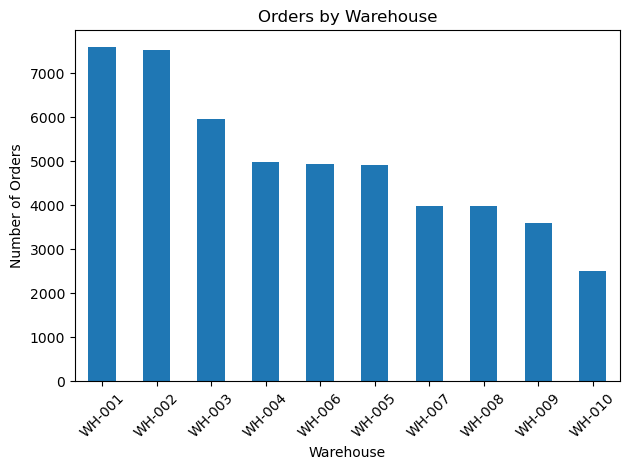

In [33]:
warehouse_orders = (
    df.groupby("warehouse_id")["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

warehouse_orders.plot(kind="bar")

plt.title("Orders by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
monthly_orders = (
    df.groupby("month_name")["order_id"]
    .nunique()
)

monthly_orders

month_name
April        4090
August       4284
December     4290
February     3859
January      4303
July         4319
June         4118
March        4219
May          4253
November     4065
October      4170
September    4030
Name: order_id, dtype: int64

In [35]:
df["processing_days"] = (
    df["warehouse_processing_hours"] / 24
)

df["delivery_performance"] = np.where(
    df["late_delivery"] == "Yes",
    "Late",
    "On Time"
)

df["order_value_category"] = pd.cut(
    df["order_value_usd"],
    bins=[0, 100, 500, 1000, np.inf],
    labels=["Low", "Medium", "High", "Very High"]
)

In [36]:
df.head()

,order_id,order_date,customer_id,customer_segment,customer_city,customer_country,warehouse_id,warehouse_city,product_category,product_weight_kg,...,delivery_attempts,warehouse_processing_hours,tracking_status,year,month,month_name,day_name,processing_days,delivery_performance,order_value_category
0,ORD-000001,2026-11-15,CUS-002353,Small Business,Tokyo,Japan,WH-004,Toronto,Home & Kitchen,8.23,...,2,25.1,Delivered,2026,11,November,Sunday,1.045833,Late,Low
1,ORD-000002,2026-04-08,CUS-003258,Consumer,Vancouver,Canada,WH-007,Paris,Beauty,0.10,...,1,25.9,Delivered,2026,4,April,Wednesday,1.079167,On Time,Medium
2,ORD-000003,2026-01-05,CUS-001221,Consumer,Houston,United States,WH-005,London,Home & Kitchen,5.51,...,1,31.5,Delivered,2026,1,January,Monday,1.312500,Late,Medium
3,ORD-000004,2026-05-29,CUS-001717,Small Business,Delhi,India,WH-002,Los Angeles,Grocery,3.75,...,1,12.6,In Transit,2026,5,May,Friday,0.525000,Late,Low
4,ORD-000005,2026-02-22,CUS-000716,Small Business,Nagoya,Japan,WH-006,Berlin,Beauty,0.10,...,1,24.9,Delivered,2026,2,February,Sunday,1.037500,Late,Low


In [38]:
df.to_csv(
    "warehouse_order_fulfillment_cleaned.csv",
    index=False
)